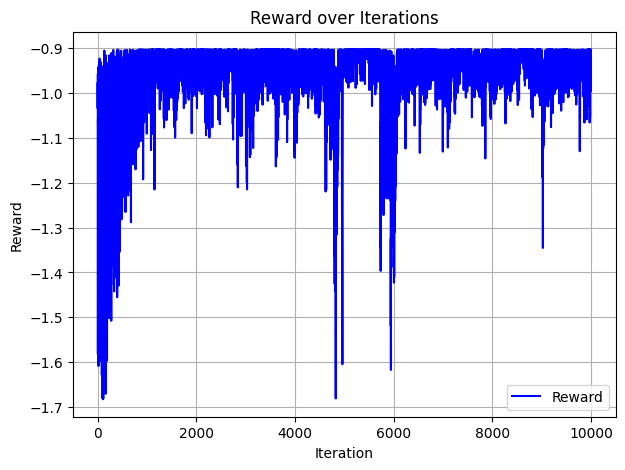

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the uploaded CSV file
file_path = "./training_results/reward.csv"
df = pd.read_csv(file_path)

# Display the first few rows to understand the structure
df.head()

# Plot REWARD vs ITERATION
plt.figure(figsize=(7, 5))
plt.plot(df['ITERATION'], df['REWARD'], label='Reward', color='b')
plt.xlabel('Iteration')
plt.ylabel('Reward')
plt.title('Reward over Iterations')
plt.grid(True)
plt.legend()
plt.show()


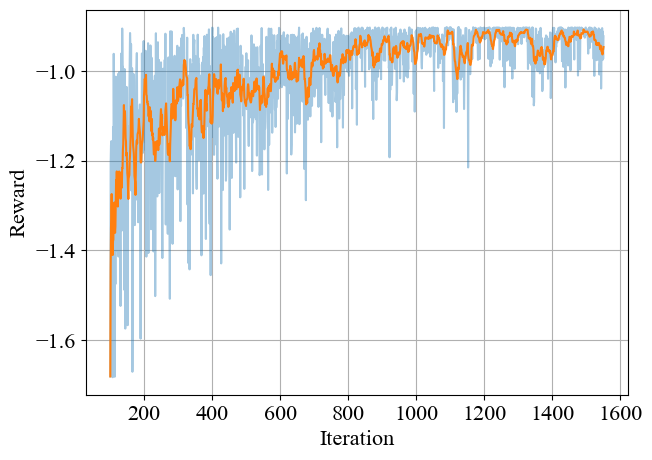

Saved smoothed plot -> ./training_results/reward_plot_smoothed.png


In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# -------- path to your CSV --------
file_path = "./training_results/reward.csv"
# ----------------------------------

if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found: {file_path}")

# Load CSV
df = pd.read_csv(file_path)

# Column names
iter_col = "ITERATION"
reward_col = "REWARD"

# ===== Restrict iteration range =====
df = df[(df[iter_col] >= 100) & (df[iter_col] <= 1550)].reset_index(drop=True)

# ===== Moving average smoothing =====
window_size = 10  # adjust this to control smoothness
df["REWARD_SMOOTH"] = df[reward_col].rolling(window=window_size, min_periods=1).mean()

# Font config
font = {
    'family': 'Times New Roman',
    'weight': 'normal',
    'size': 16
}
plt.rc('font', **font)

# Plot raw + smoothed
plt.figure(figsize=(7, 5))
plt.plot(df[iter_col], df[reward_col], label="Reward (raw)", alpha=0.4)
plt.plot(df[iter_col], df["REWARD_SMOOTH"], label=f"Reward (window={window_size})")
plt.xlabel("Iteration")
plt.ylabel("Reward")
# plt.title("Reward")
plt.grid(True)
# plt.legend()

# Save and show
out_path = "./training_results/reward_plot_smoothed.png"
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved smoothed plot -> {out_path}")
